In [1]:
%pip install -q qiskit qiskit-aer


In [2]:
import qiskit
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

print("Qiskit version:", qiskit.__version__)
print("Environment ready!")

Qiskit version: 2.5.2
Environment ready!


In [3]:
from qiskit import QuantumCircuit

# Create a circuit with 1 qubit and 1 classical bit
qc = QuantumCircuit(1, 1)

# Measure the qubit and store the result
qc.measure(0, 0)

# Display the circuit
print(qc.draw())

     ┌─┐
  q: ┤M├
     └╥┘
c: 1/═╩═
      0 


In [4]:
from qiskit_aer import AerSimulator

simulator = AerSimulator()

result = simulator.run(
    qc,
    shots=1000
).result()

counts = result.get_counts()

print(counts)

{'0': 1000}


In [5]:
qc_x = QuantumCircuit(1, 1)

qc_x.x(0)          # Apply X gate to qubit 0
qc_x.measure(0, 0)

print(qc_x.draw())

result_x = simulator.run(
    qc_x,
    shots=1000
).result()

print(result_x.get_counts())

     ┌───┐┌─┐
  q: ┤ X ├┤M├
     └───┘└╥┘
c: 1/══════╩═
           0 
{'1': 1000}


     ┌───┐┌─┐
  q: ┤ H ├┤M├
     └───┘└╥┘
c: 1/══════╩═
           0 
{'1': 505, '0': 495}


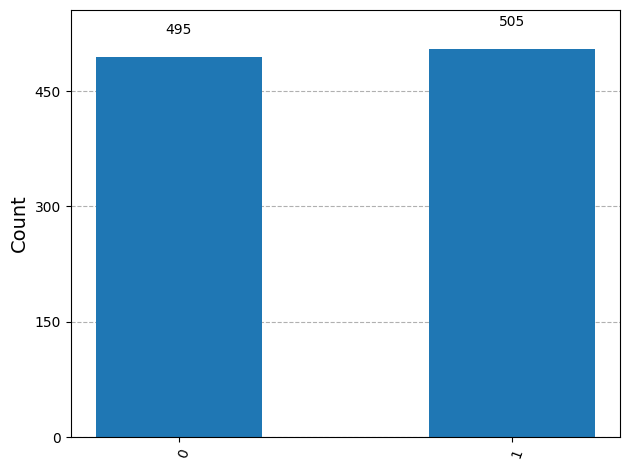

In [6]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

qc_h = QuantumCircuit(1, 1)
qc_h.h(0)
qc_h.measure(0, 0)

print(qc_h.draw())

simulator = AerSimulator()
result = simulator.run(qc_h, shots=1000).result()
counts = result.get_counts()

print(counts)
plot_histogram(counts)

In [7]:
qc_h2 = QuantumCircuit(1, 1)
qc_h2.h(0)
qc_h2.h(0)
qc_h2.measure(0, 0)

result = simulator.run(qc_h2, shots=1000).result()
print(result.get_counts())


{'0': 1000}


In [8]:
qc_z = QuantumCircuit(1, 1)
qc_z.h(0)
qc_z.z(0)
qc_z.h(0)
qc_z.measure(0, 0)

result_z = simulator.run(qc_z, shots=1000).result()
print(result_z.get_counts())

{'1': 1000}


In [9]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

simulator = AerSimulator()

# Test the S gate
qc_s = QuantumCircuit(1, 1)
qc_s.h(0)
qc_s.s(0)
qc_s.h(0)
qc_s.measure(0, 0)

result_s = simulator.run(qc_s, shots=1000).result()
print("S gate:", result_s.get_counts())

# Test the T gate
qc_t = QuantumCircuit(1, 1)
qc_t.h(0)
qc_t.t(0)
qc_t.h(0)
qc_t.measure(0, 0)

result_t = simulator.run(qc_t, shots=1000).result()
print("T gate:", result_t.get_counts())


S gate: {'1': 523, '0': 477}
T gate: {'1': 154, '0': 846}


In [10]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

qc_bell = QuantumCircuit(2, 2)

qc_bell.h(0)
qc_bell.cx(0, 1)

qc_bell.measure([0, 1], [0, 1])

print(qc_bell.draw())

simulator = AerSimulator()
result = simulator.run(qc_bell, shots=1000).result()
print(result.get_counts())

     ┌───┐     ┌─┐   
q_0: ┤ H ├──■──┤M├───
     └───┘┌─┴─┐└╥┘┌─┐
q_1: ─────┤ X ├─╫─┤M├
          └───┘ ║ └╥┘
c: 2/═══════════╩══╩═
                0  1 
{'11': 504, '00': 496}


In [11]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

qc_bell = QuantumCircuit(2)
qc_bell.h(0)
qc_bell.cx(0, 1)

qc_bell.save_statevector()

simulator = AerSimulator(method="statevector")
result = simulator.run(qc_bell).result()

state = result.get_statevector()
print(state)

Statevector([0.70710678+0.j, 0.        +0.j, 0.        +0.j,
             0.70710678+0.j],
            dims=(2, 2))


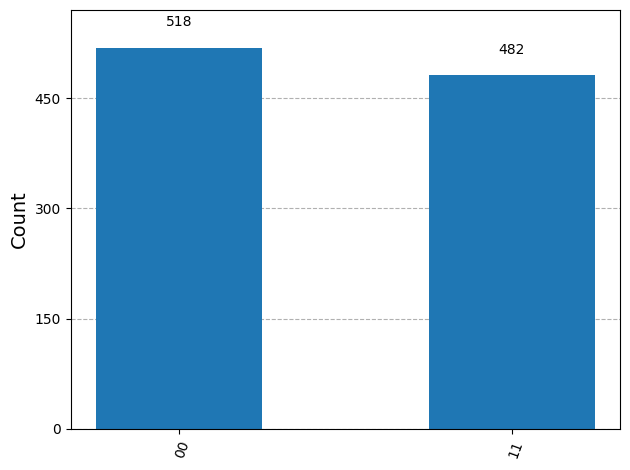

In [12]:
from qiskit.visualization import plot_histogram

qc_bell_measured = QuantumCircuit(2, 2)
qc_bell_measured.h(0)
qc_bell_measured.cx(0, 1)
qc_bell_measured.measure([0, 1], [0, 1])

result = simulator.run(
    qc_bell_measured, shots=1000
).result()

counts = result.get_counts()
plot_histogram(counts)

In [13]:
qc_ghz = QuantumCircuit(3, 3)

qc_ghz.h(0)
qc_ghz.cx(0, 1)
qc_ghz.cx(0, 2)

qc_ghz.measure([0, 1, 2], [0, 1, 2])

result = simulator.run(qc_ghz, shots=1000).result()
print(result.get_counts())

{'111': 518, '000': 482}


In [14]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

simulator = AerSimulator()

# Test 1: X gate should turn |0> into |1>
qc_x = QuantumCircuit(1, 1)
qc_x.x(0)
qc_x.measure(0, 0)

counts_x = simulator.run(qc_x, shots=100).result().get_counts()
assert counts_x == {"1": 100}
print("X gate test passed!")

# Test 2: Two H gates should return |0>
qc_hh = QuantumCircuit(1, 1)
qc_hh.h(0)
qc_hh.h(0)
qc_hh.measure(0, 0)

counts_hh = simulator.run(qc_hh, shots=100).result().get_counts()
assert counts_hh == {"0": 100}
print("Double-H test passed!")

X gate test passed!
Double-H test passed!



# Day 1: Quantum Foundations

## Concepts learned
- Qubits and measurement
- X and Hadamard gates
- Phase gates: Z, S, and T
- Bell-state entanglement
- Three-qubit GHZ state

## Experiments
- Tested X and double-H circuits
- Measured Bell-state outcomes
- Built a three-qubit GHZ circuit

## Key understanding
Quantum gates transform quantum states.
Measurement converts quantum information into classical outcomes.
Entangled qubits can show correlations that independent classical bits cannot reproduce.

## Next steps
- Review gate matrices
- Study quantum circuit diagrams
- Learn the mathematics of measurement


In [15]:
import numpy as np

X = np.array([
    [0, 1],
    [1, 0]
])

zero = np.array([1, 0])
one = np.array([0, 1])

print("X |0> =", X @ zero)
print("X |1> =", X @ one)

X |0> = [0 1]
X |1> = [1 0]


In [16]:
import numpy as np

H = (1 / np.sqrt(2)) * np.array([
    [1,  1],
    [1, -1]
])

zero = np.array([1, 0])
one = np.array([0, 1])

print("H|0> =", H @ zero)
print("H|1> =", H @ one)


H|0> = [0.70710678 0.70710678]
H|1> = [ 0.70710678 -0.70710678]


In [17]:
state = H @ zero
probabilities = np.abs(state) ** 2

print("State:", state)
print("Probabilities:", probabilities)
print("Total:", probabilities.sum())

State: [0.70710678 0.70710678]
Probabilities: [0.5 0.5]
Total: 0.9999999999999998


In [18]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

simulator = AerSimulator()

qc_error = QuantumCircuit(1, 1)
qc_error.x(0)          # Simulate a bit-flip error
qc_error.measure(0, 0)

result = simulator.run(
    qc_error, shots=100
).result()

print(result.get_counts())

{'1': 100}


In [19]:
qc_compare = QuantumCircuit(1, 1)
qc_compare.x(0)
qc_compare.measure(0, 0)

print(simulator.run(
    qc_compare, shots=100
).result().get_counts())

{'1': 100}


In [20]:

from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

simulator = AerSimulator()

for run_number in range(1, 4):
    bell = QuantumCircuit(2, 2)
    bell.h(0)
    bell.cx(0, 1)
    bell.measure([0, 1], [0, 1])

    counts = simulator.run(
        bell, shots=2000
    ).result().get_counts()

    print(f"Run {run_number}: {counts}")
    assert sum(counts.values()) == 2000
    assert set(counts).issubset({"00", "11"})

print("All three Bell experiments passed!")


Run 1: {'11': 938, '00': 1062}
Run 2: {'00': 1002, '11': 998}
Run 3: {'11': 980, '00': 1020}
All three Bell experiments passed!


In [21]:

%pip install matplotlib


In [22]:

from qiskit.visualization import circuit_drawer

print("Bell circuit exists:", "bell" in globals())
print("GHZ circuit exists:", "ghz" in globals())


Bell circuit exists: True
GHZ circuit exists: False


In [23]:

print("Bell circuit exists:", "bell" in globals())
print("GHZ circuit exists:", "ghz" in globals())


Bell circuit exists: True
GHZ circuit exists: False


In [24]:

from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

simulator = AerSimulator()

ghz_variant = QuantumCircuit(3, 3)
ghz_variant.h(0)
ghz_variant.cx(0, 1)
# The second CNOT is intentionally removed.
ghz_variant.measure([0, 1, 2], [0, 1, 2])

variant_counts = simulator.run(
    ghz_variant, shots=2000
).result().get_counts()

print("GHZ variation counts:", variant_counts)
print(ghz_variant.draw())

assert sum(variant_counts.values()) == 2000
assert set(variant_counts).issubset({"000", "011", "100", "111", "000", "110"})


GHZ variation counts: {'011': 1037, '000': 963}
     ┌───┐     ┌─┐   
q_0: ┤ H ├──■──┤M├───
     └───┘┌─┴─┐└╥┘┌─┐
q_1: ─────┤ X ├─╫─┤M├
      ┌─┐ └───┘ ║ └╥┘
q_2: ─┤M├───────╫──╫─
      └╥┘       ║  ║ 
c: 3/══╩════════╩══╩═
       2        0  1 


In [25]:

from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

simulator = AerSimulator()

# Create a fresh 3-qubit circuit
ghz_variant2 = QuantumCircuit(3, 3)

# Replace the Hadamard gate with an X gate
ghz_variant2.x(0)

# Keep both CNOT gates
ghz_variant2.cx(0, 1)
ghz_variant2.cx(0, 2)

# Measure all three qubits
ghz_variant2.measure([0, 1, 2], [0, 1, 2])

# Run the simulation
variant2_counts = simulator.run(
    ghz_variant2, shots=2000
).result().get_counts()

print("GHZ Variation 2 counts:", variant2_counts)
print(ghz_variant2.draw())

assert variant2_counts == {"111": 2000}
print("GHZ Variation 2 test passed!")


GHZ Variation 2 counts: {'111': 2000}
     ┌───┐             ┌─┐   
q_0: ┤ X ├──■────■─────┤M├───
     └───┘┌─┴─┐  │  ┌─┐└╥┘   
q_1: ─────┤ X ├──┼──┤M├─╫────
          └───┘┌─┴─┐└╥┘ ║ ┌─┐
q_2: ──────────┤ X ├─╫──╫─┤M├
               └───┘ ║  ║ └╥┘
c: 3/════════════════╩══╩══╩═
                     1  0  2 
GHZ Variation 2 test passed!


### Day 1 — Testing and Debugging Reflection

**Issue 1: Circuit visualization error**
- **Problem:** The Bell and GHZ circuits initially failed to display with `draw("mpl")`.
- **Resolution:** Installed Matplotlib and used Qiskit's text-based `draw()` method.
- **Lesson:** When one visualization method fails, test a simpler alternative before rebuilding the circuit.

**Issue 2: Undefined circuit variable**
- **Problem:** `NameError: name 'ghz_variant2' is not defined`.
- **Resolution:** Created `ghz_variant2` before applying gates.
- **Lesson:** Python variables must be defined before they are used.

**Sampling versus mathematical state**
- An ideal Bell state predicts equal probabilities for outcomes `00` and `11`.
- A finite simulation with 2,000 shots may produce counts such as 1,007 and 993 rather than exactly 1,000 each.
- The counts are sampled observations; the mathematical state determines the predicted probabilities.

**Day 1 reflection**
I practiced building, measuring, drawing, testing and modifying quantum circuits. I used assertions to check measurement totals and allowed outcomes. My next step is to organize the notebook and document the experiments in a GitHub portfolio.